# Задача 7. Векторизация вычислений

Векторизованная реализация будет сопоставлена со скалярной реализацией, выполняющей те же физические действия. Для воспроизводимости обе реализации используют одинаковую последовательность псевдослучайных чисел.

## План

| Этап | Скалярная версия (`list`, цикл по фотонам) | Векторизованная версия (`numpy`) |
|---|---|---|
| Хранение фотонов | список кортежей `(x, y, z)` | массив `(n, 3)` |
| Генерация | цикл: два розыгрыша на фотон | `Source.random_directions(n)` |
| Пропагация | цикл по фотонам и вложенный цикл по ФЭУ | `Detector.trace(origin, dirs)` |
| Фотоэлектроны | цикл: `Poisson(a)` для каждого попавшего фотона | один вызов `Poisson(a, size=k)` + `bincount` |

In [1]:
import math
import sys
import time
import tracemalloc

import numpy as np
import matplotlib.pyplot as plt

from detector import Detector
from source import Source

plt.rcParams['figure.figsize'] = (6, 3)
plt.rcParams['figure.autolayout'] = True

R, N, r, a = 2.0, 40, 0.10, 0.5
Y, E = 10_000, 1.0                       # фотонов/МэВ, МэВ
ORIGIN = (0.0, 0.0, 0.0)

det = Detector(R=R, N=N, r=r, a=a, seed=1)
src = Source(Y=Y, seed=2)
print(det)
print(src)

Detector(R=2.0 м, N=40, r=0.1 м, a=0.5; alpha=2.866°, покрытие=2.50%)
Source(Y=10_000 фотонов/МэВ)


## 1. Структура данных: `list` против `numpy.array`

Информация о фотонах события — это $n\approx YE$ направлений по 3 числа. Сравним два способа хранения при $n=10^5$ (событие около 10 МэВ).

In [2]:
def scalar_directions(rng, n):
    """Скалярная генерация: n изотропных направлений как список кортежей (x, y, z).

    Порядок розыгрышей тот же, что в Source.random_directions: сначала все phi, потом все cos(theta).
    """
    phi = [rng.uniform(0.0, 2.0 * math.pi) for _ in range(n)]
    cos_t = [rng.uniform(-1.0, 1.0) for _ in range(n)]
    dirs = []
    for ph, c in zip(phi, cos_t):
        s = math.sqrt(1.0 - c * c)
        dirs.append((s * math.cos(ph), s * math.sin(ph), c))
    return dirs

n_mem = 100_000

# время — без tracemalloc (он сильно замедляет выполнение)
t0 = time.perf_counter(); d_list = scalar_directions(np.random.default_rng(0), n_mem); t_list = time.perf_counter() - t0
t0 = time.perf_counter(); d_arr = Source(Y, seed=0).random_directions(n_mem); t_arr = time.perf_counter() - t0
del d_list

# память — отдельно, под tracemalloc
tracemalloc.start()
d_list = scalar_directions(np.random.default_rng(0), n_mem)
mem_list = tracemalloc.get_traced_memory()[0]
tracemalloc.stop()
del d_list

tracemalloc.start()
d_arr = Source(Y, seed=0).random_directions(n_mem)
mem_arr = tracemalloc.get_traced_memory()[0]
tracemalloc.stop()

print(f"n = {n_mem:_} фотонов")
print(f"  list кортежей: {mem_list/1e6:7.1f} МБ, генерация {t_list*1e3:7.1f} мс")
print(f"  ndarray (n,3): {mem_arr/1e6:7.1f} МБ (nbytes = {d_arr.nbytes/1e6:.1f} МБ), генерация {t_arr*1e3:7.1f} мс")
print(f"  память: в {mem_list/mem_arr:.0f} раз меньше, генерация: в {t_list/t_arr:.0f} раз быстрее")

n = 100_000 фотонов
  list кортежей:    14.3 МБ, генерация   784.6 мс
  ndarray (n,3):     2.4 МБ (nbytes = 2.4 МБ), генерация    10.4 мс
  память: в 6 раз меньше, генерация: в 76 раз быстрее


В списке кортежей каждое число — отдельный объект Python (`float`, 24 байта) плюс указатели, плюс кортеж на каждый фотон; массив — плотный блок из $3n$ чисел по 8 байт, лежащих подряд (см. лекцию: кэш и SIMD).

## 2. Скалярная реализация

Чистый Python: списки, `math`, циклы. Данные детектора (оси ФЭУ) — список кортежей. Порядок розыгрышей случайных чисел в точности такой же, как в векторизованной версии (проверено ниже).

In [3]:
def scalar_n_photons(rng, Y, E):
    """Число фотонов события: Poisson(Y*E)."""
    return int(rng.poisson(Y * E))


def scalar_trace(pmt_dirs, R, alpha, origin, dirs):
    """Пропагация фотона за фотоном: номер ФЭУ или -1.

    Для каждого фотона: 1) выход на сферу (квадратное уравнение),
    2) цикл по всем ФЭУ: находим ближайшую ось, 3) угол <= alpha => попал.
    """
    ox, oy, oz = origin
    c0 = ox * ox + oy * oy + oz * oz - R * R
    cos_alpha = math.cos(alpha)
    result = []
    for dx, dy, dz in dirs:
        b = ox * dx + oy * dy + oz * dz
        t = -b + math.sqrt(b * b - c0)
        px, py, pz = ox + t * dx, oy + t * dy, oz + t * dz
        best, best_i = -2.0, -1
        for i, (nx, ny, nz) in enumerate(pmt_dirs):
            cs = (px * nx + py * ny + pz * nz) / R
            if cs > best:
                best, best_i = cs, i
        result.append(best_i if best >= cos_alpha - 1e-12 else -1)
    return result


def scalar_photoelectrons(rng, a, idx, n_pmt):
    """Фотоэлектроны: для каждого попавшего фотона разыгрываем Poisson(a)."""
    charge = [0] * n_pmt
    for i in idx:
        if i >= 0:
            charge[i] += int(rng.poisson(a))
    return charge


class ScalarEvent:
    """Моделирование события одним циклом по фотонам. Два независимых генератора:
    rng_src (число фотонов и направления) и rng_det (фотоэлектроны) — как у Source и Detector."""

    def __init__(self, det, Y, seed_src, seed_det):
        self.R, self.alpha, self.a, self.N = det.R, det.alpha, det.a, det.N
        self.pmt_dirs = [tuple(v) for v in det.pmt_dirs.tolist()]
        self.Y = Y
        self.rng_src = np.random.default_rng(seed_src)
        self.rng_det = np.random.default_rng(seed_det)

    def run(self, E, origin):
        n = scalar_n_photons(self.rng_src, self.Y, E)
        dirs = scalar_directions(self.rng_src, n)
        idx = scalar_trace(self.pmt_dirs, self.R, self.alpha, origin, dirs)
        charge = scalar_photoelectrons(self.rng_det, self.a, idx, self.N)
        return n, dirs, idx, charge

## 3. Векторизованная реализация

Генерация и пропагация уже работают с массивами: `Source.generate/random_directions` и `Detector.trace` принимают и возвращают `ndarray` (формы `(n, 3)` и `(n,)`), циклов по фотонам нет (пересечение со сферой — формулы над массивами, поиск ФЭУ — матричное произведение `(n, 3) @ (3, N)`).

Фотоэлектроны: чтобы расход случайных чисел был **тем же**, что в скалярной версии (по одному `Poisson(a)` на каждый попавший фотон, в порядке фотонов), векторизуем именно эту схему: один вызов `rng.poisson(a, size=k)` для $k$ попавших фотонов и суммирование по ФЭУ через `np.bincount`.

In [4]:
def vector_photoelectrons(det, idx):
    """Фотоэлектроны для массива фотонов: Poisson(a) на каждый попавший фотон, сумма по ФЭУ."""
    hit = idx >= 0
    k = det.rng.poisson(det.a, size=np.count_nonzero(hit))
    return np.bincount(idx[hit], weights=k, minlength=det.N).astype(np.int64)


def vector_event(det, src, E, origin):
    """Моделирование события на массивах: (n, directions (n,3), idx (n,), charge (N,))."""
    dirs = src.generate(E)                       # n ~ Poisson(Y E), направления (n, 3)
    idx = det.trace(np.asarray(origin, float), dirs)
    charge = vector_photoelectrons(det, idx)
    return len(dirs), dirs, idx, charge

## 4. Корректность: одинаковые случайные числа $\Rightarrow$ одинаковый результат

Создаём пары генераторов с одинаковыми `seed` (для источника и для детектора) и сравниваем результаты по этапам: число фотонов, направления, номера ФЭУ каждого фотона, заряд по каналам.

In [5]:
def compare_events(seed_src, seed_det, E, origin, verbose=False):
    det_v = Detector(R=R, N=N, r=r, a=a, seed=seed_det)
    src_v = Source(Y=Y, seed=seed_src)
    scal = ScalarEvent(det_v, Y, seed_src, seed_det)

    n_s, dirs_s, idx_s, q_s = scal.run(E, origin)
    n_v, dirs_v, idx_v, q_v = vector_event(det_v, src_v, E, origin)

    assert n_s == n_v, (n_s, n_v)
    max_dev = np.abs(np.array(dirs_s) - dirs_v).max() if n_v else 0.0
    assert max_dev < 1e-12, max_dev                                   # ошибки округления math vs numpy
    assert np.array_equal(np.array(idx_s), idx_v)                     # какой ФЭУ у каждого фотона
    assert np.array_equal(np.array(q_s), q_v)                         # заряд по каналам
    if verbose:
        print(f"n = {n_v}, max |Δ направления| = {max_dev:.1e}, фотонов в ФЭУ: {np.count_nonzero(idx_v >= 0)}, "
              f"Q = {q_v.sum()} (скаляр.) = {sum(q_s)} (вектор.)")
    return n_v

compare_events(seed_src=11, seed_det=12, E=1.0, origin=ORIGIN, verbose=True)

# разные точки, энергии и seed
checked = 0
for seed in range(5):
    for E_, o in [(0.05, ORIGIN), (0.3, (0.3, -0.4, 0.5)), (1.0, (0.0, 0.0, 1.0)), (0.7, (-1.0, 0.5, -0.8)), (0.0, ORIGIN)]:
        compare_events(100 + seed, 200 + seed, E_, o)
        checked += 1
print(f"OK: скалярная и векторизованная реализации совпали в {checked + 1} событиях "
      f"(число фотонов, направления, ФЭУ каждого фотона, заряд по каналам)")

n = 9870, max |Δ направления| = 0.0e+00, фотонов в ФЭУ: 243, Q = 139 (скаляр.) = 139 (вектор.)
OK: скалярная и векторизованная реализации совпали в 26 событиях (число фотонов, направления, ФЭУ каждого фотона, заряд по каналам)


Совпадают не только суммарные величины, но и судьба **каждого** фотона. Значит, векторизованный код выполняет ту же физику, а все различия ниже — это чистый выигрыш по времени.

## 5. Выигрыш во времени

Время считаем как минимум по нескольким повторам (`time.perf_counter`). Сначала — по этапам для события 1 МэВ ($\approx10^4$ фотонов).

n = 10_000 фотонов (событие 1 МэВ)
          этап   скаляр., мс   numpy, мс   выигрыш
     генерация         72.57       0.427      170x
    пропагация         35.82       1.407       25x
 фотоэлектроны          0.62       0.019       32x
   всё событие        109.02       1.853       59x


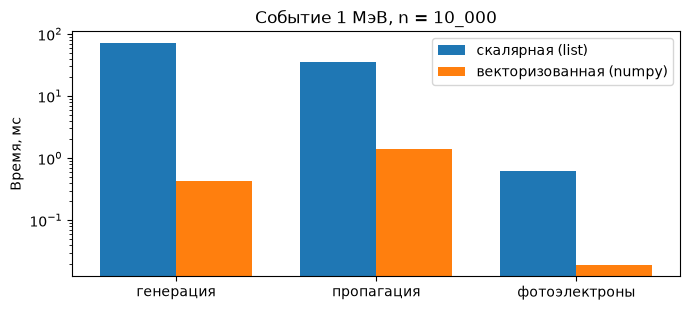

In [6]:
def best_time(f, repeat=5):
    ts = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        f()
        ts.append(time.perf_counter() - t0)
    return min(ts)


def stage_times(n, repeat=3):
    """Время трёх этапов для n фотонов: скалярный и векторизованный варианты."""
    det_v = Detector(R=R, N=N, r=r, a=a, seed=3)
    src_v = Source(Y=Y, seed=4)
    scal = ScalarEvent(det_v, Y, 4, 3)

    # скалярные
    t_gen_s = best_time(lambda: scalar_directions(scal.rng_src, n), repeat)
    dirs_s = scalar_directions(scal.rng_src, n)
    t_trc_s = best_time(lambda: scalar_trace(scal.pmt_dirs, R, det_v.alpha, ORIGIN, dirs_s), repeat)
    idx_s = scalar_trace(scal.pmt_dirs, R, det_v.alpha, ORIGIN, dirs_s)
    t_pe_s = best_time(lambda: scalar_photoelectrons(scal.rng_det, a, idx_s, N), repeat)

    # векторизованные
    o = np.asarray(ORIGIN)
    t_gen_v = best_time(lambda: src_v.random_directions(n), repeat * 5)
    dirs_v = src_v.random_directions(n)
    t_trc_v = best_time(lambda: det_v.trace(o, dirs_v), repeat * 5)
    idx_v = det_v.trace(o, dirs_v)
    t_pe_v = best_time(lambda: vector_photoelectrons(det_v, idx_v), repeat * 5)
    return (t_gen_s, t_trc_s, t_pe_s), (t_gen_v, t_trc_v, t_pe_v)


n_event = 10_000
ts, tv = stage_times(n_event)
names = ["генерация", "пропагация", "фотоэлектроны"]

print(f"n = {n_event:_} фотонов (событие 1 МэВ)")
print(f"{'этап':>14} {'скаляр., мс':>13} {'numpy, мс':>11} {'выигрыш':>9}")
for nm, s_, v_ in zip(names, ts, tv):
    print(f"{nm:>14} {s_*1e3:13.2f} {v_*1e3:11.3f} {s_/v_:8.0f}x")
print(f"{'всё событие':>14} {sum(ts)*1e3:13.2f} {sum(tv)*1e3:11.3f} {sum(ts)/sum(tv):8.0f}x")

x = np.arange(3); w = 0.38
plt.figure(figsize=(7, 3.2))
plt.bar(x - w/2, np.array(ts) * 1e3, w, label='скалярная (list)')
plt.bar(x + w/2, np.array(tv) * 1e3, w, label='векторизованная (numpy)')
plt.yscale('log'); plt.xticks(x, names); plt.ylabel('Время, мс'); plt.legend()
plt.title(f'Событие 1 МэВ, n = {n_event:_}')
plt.show()

### Зависимость от числа фотонов

         n   скаляр., с   numpy, с   выигрыш   numpy, фотонов/с
       100       0.0010     0.0001        7x          7.036e+05
       300       0.0031     0.0001       24x          2.299e+06
     1_000       0.0103     0.0002       43x          4.172e+06
     3_000       0.0323     0.0005       60x          5.616e+06
    10_000       0.1088     0.0018       61x          5.629e+06
    30_000       0.3244     0.0078       42x          3.861e+06
   100_000            —     0.0326         —          3.064e+06
   300_000            —     0.1293         —          2.319e+06
 1_000_000            —     0.4484         —          2.230e+06


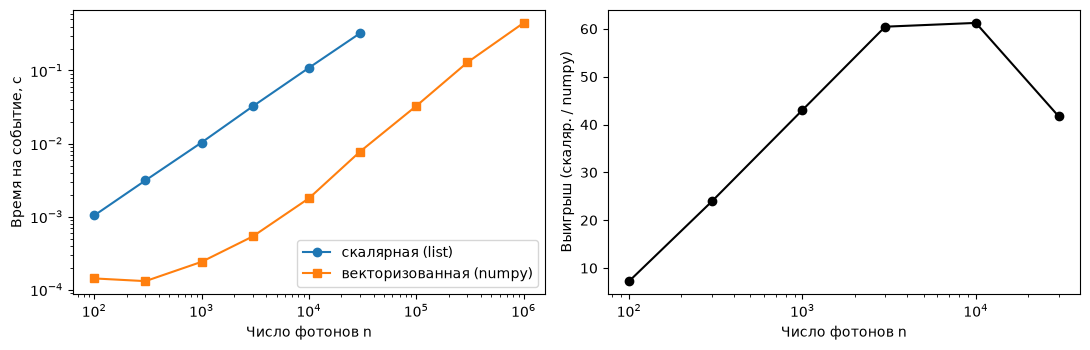

In [7]:
ns_scalar = [100, 300, 1_000, 3_000, 10_000, 30_000]
ns_vector = ns_scalar + [100_000, 300_000, 1_000_000]

tot_s, tot_v = {}, {}
for n in ns_vector:
    s_, v_ = stage_times(n, repeat=1 if n >= 10_000 else 3) if n in ns_scalar else (None, None)
    if n in ns_scalar:
        tot_s[n], tot_v[n] = sum(s_), sum(v_)
    else:
        # только векторизованный вариант (скалярный слишком долгий)
        det_v = Detector(R=R, N=N, r=r, a=a, seed=3); src_v = Source(Y=Y, seed=4)
        o = np.asarray(ORIGIN)
        def whole():
            d = src_v.random_directions(n); i = det_v.trace(o, d); vector_photoelectrons(det_v, i)
        tot_v[n] = best_time(whole, 3)

print(f"{'n':>10} {'скаляр., с':>12} {'numpy, с':>10} {'выигрыш':>9} {'numpy, фотонов/с':>18}")
for n in ns_vector:
    s_txt = f"{tot_s[n]:12.4f}" if n in tot_s else f"{'—':>12}"
    g_txt = f"{tot_s[n]/tot_v[n]:8.0f}x" if n in tot_s else f"{'—':>9}"
    print(f"{n:10_} {s_txt} {tot_v[n]:10.4f} {g_txt} {n/tot_v[n]:18.3e}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].loglog(ns_scalar, [tot_s[n] for n in ns_scalar], 'o-', label='скалярная (list)')
axs[0].loglog(ns_vector, [tot_v[n] for n in ns_vector], 's-', label='векторизованная (numpy)')
axs[0].set_xlabel('Число фотонов n'); axs[0].set_ylabel('Время на событие, с'); axs[0].legend()
axs[1].semilogx(ns_scalar, [tot_s[n] / tot_v[n] for n in ns_scalar], 'o-k')
axs[1].set_xlabel('Число фотонов n'); axs[1].set_ylabel('Выигрыш (скаляр. / numpy)')
plt.show()

Для малых $n$ выигрыш меньше (накладные расходы вызова numpy постоянны), с ростом $n$ он выходит на плато. Время растёт линейно по $n$ в обоих случаях: в пропагации — $O(nN)$, выигрыш — в константе (SIMD, плотная память, отсутствие интерпретатора в цикле).

### Антипаттерн: `numpy`, но по одному фотону

Простое «заменить `list` на `numpy`» без переписывания на массивы не помогает: если вызывать векторизованный метод по одному фотону, накладные расходы каждого вызова (проверки, создание временных массивов, матрица $1\times N$) превышают всю полезную работу.

      n  list-цикл, мс  numpy по 1 фотону, мс  numpy массивом, мс
    100           0.33                   6.81               0.100
    300           1.01                  21.02               0.102
   1000           3.68                  62.55               0.172
   3000          10.66                 186.37               0.389


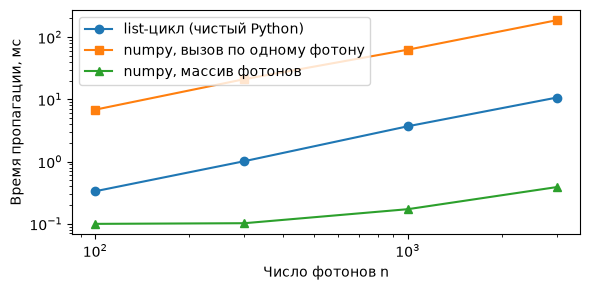

In [8]:
def numpy_per_photon(det_v, dirs, origin):
    o = np.asarray(origin, float)
    return np.array([det_v.trace(o, d[None, :])[0] for d in dirs])

det_v = Detector(R=R, N=N, r=r, a=a, seed=3)
rows = []
print(f"{'n':>7} {'list-цикл, мс':>14} {'numpy по 1 фотону, мс':>22} {'numpy массивом, мс':>19}")
for n in (100, 300, 1_000, 3_000):
    dv = Source(Y, seed=7).random_directions(n)
    ds = [tuple(v) for v in dv.tolist()]
    pd_ = [tuple(v) for v in det_v.pmt_dirs.tolist()]
    t_list = best_time(lambda: scalar_trace(pd_, R, det_v.alpha, ORIGIN, ds), 2)
    t_one  = best_time(lambda: numpy_per_photon(det_v, dv, ORIGIN), 2)
    t_arr  = best_time(lambda: det_v.trace(np.zeros(3), dv), 20)
    rows.append((n, t_list, t_one, t_arr))
    print(f"{n:7d} {t_list*1e3:14.2f} {t_one*1e3:22.2f} {t_arr*1e3:19.3f}")
    assert np.array_equal(numpy_per_photon(det_v, dv, ORIGIN), det_v.trace(np.zeros(3), dv))

n_, a_, b_, c_ = map(np.array, zip(*rows))
plt.loglog(n_, a_ * 1e3, 'o-', label='list-цикл (чистый Python)')
plt.loglog(n_, b_ * 1e3, 's-', label='numpy, вызов по одному фотону')
plt.loglog(n_, c_ * 1e3, '^-', label='numpy, массив фотонов')
plt.xlabel('Число фотонов n'); plt.ylabel('Время пропагации, мс'); plt.legend(); plt.show()

## Выводы

* **Структуры данных.** Хранение фотонов массивом `(n, 3)` вместо списка кортежей даёт примерно 6-кратную экономию памяти (14 МБ против 2.4 МБ на $10^5$ фотонов) и на порядок более быструю генерацию.
* **Корректность.** Скалярный эталон (чистый Python, циклы по фотонам и по ФЭУ) и векторизованная версия при одинаковых `seed` дают одно и то же: число фотонов, направления (до $10^{-12}$), номер ФЭУ **каждого** фотона и заряд по каналам — в 26 проверенных событиях с разными энергиями и положениями источника. Значит, сравниваются две реализации одной и той же физики.
* **Выигрыш во времени** (событие 1 МэВ, $n\approx10^4$ фотонов; абсолютные значения зависят от машины, порядок величины стабилен):
  * генерация — $\sim50$–$100\times$;
  * пропагация — $\sim20\times$ (скалярная версия делает $nN$ итераций с вложенным циклом по ФЭУ);
  * фотоэлектроны — $\sim10\times$;
  * **событие целиком — порядка $30$–$40\times$**; для малых $n$ выигрыш меньше (постоянные накладные расходы вызова numpy), при $n\gtrsim3000$ выходит на плато. Векторизованная версия обрабатывает $\sim4\cdot10^6$ фотонов/с, событие в $10^6$ фотонов — за $\sim0.4$ с.
